<h1>用卷积网络识别图像<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#引言" data-toc-modified-id="引言-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>引言</a></span></li><li><span><a href="#卷积网络--手写数字识别" data-toc-modified-id="卷积网络--手写数字识别-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>卷积网络--手写数字识别</a></span><ul class="toc-item"><li><span><a href="#准备工作——模块引用" data-toc-modified-id="准备工作——模块引用-2.1"><span class="toc-item-num">2.1&nbsp;&nbsp;</span>准备工作——模块引用</a></span></li><li><span><a href="#准备工作——下载数据" data-toc-modified-id="准备工作——下载数据-2.2"><span class="toc-item-num">2.2&nbsp;&nbsp;</span>准备工作——下载数据</a></span></li><li><span><a href="#生成模型" data-toc-modified-id="生成模型-2.3"><span class="toc-item-num">2.3&nbsp;&nbsp;</span>生成模型</a></span></li><li><span><a href="#模型训练测试" data-toc-modified-id="模型训练测试-2.4"><span class="toc-item-num">2.4&nbsp;&nbsp;</span>模型训练测试</a></span></li></ul></li></ul></div>

## 引言

    我们在前面学习了神经网络，用神经网络来识别手写数字，每副手写数字的图片大小都是28x28，神经网络全连接层需要用到784个参数。如果要识别的图像是96X96呢？或者是1024X1024呢？那深层网络中的计算量是否可以想象到有多大。因此，我们需要引入一种能能减少计算量的网络，那这种能够共享权值的卷积网络就进入我们的视野。

## 卷积网络--手写数字识别

### 准备工作——模块引用

In [138]:
import numpy as np
import time
from keras.datasets import mnist
from keras.utils import np_utils
from keras.models import Sequential
from keras.layers import Dense, Activation, Convolution2D, MaxPooling2D, Flatten
from keras.optimizers import Adam


### 准备工作——下载数据

In [139]:
np.random.seed(int(time.time()))
# 下载 mnist 数据集 to the path '~/.keras/datasets/'
# 加载数据
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# data pre-processing 数据预处理


In [140]:
X_train.shape

(60000, 28, 28)

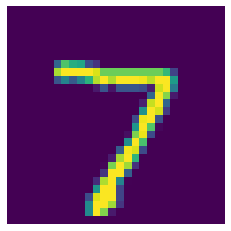

In [144]:
plt.imshow(X_test[0])
plt.axis('off')
plt.show()

In [143]:
y_test

array([7, 2, 1, ..., 4, 5, 6], dtype=uint8)

归一化数据，并把标识转换成独热码

In [ ]:

X_train=np.where(X_train.reshape(-1, 28, 28,1)>127,1,0)
X_test=np.where(X_test.reshape(-1,28, 28,1)>127,1,0)
y_train = np_utils.to_categorical(y_train, num_classes=10) 
y_test = np_utils.to_categorical(y_test, num_classes=10)

In [145]:
X_train = X_train.reshape(-1, 28, 28,1)/255. 
X_test = X_test.reshape(-1,28, 28,1)/255.   
y_train = np_utils.to_categorical(y_train, num_classes=10) 
y_test = np_utils.to_categorical(y_test, num_classes=10)

In [146]:
y_test

array([[0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

### 生成模型

Sequential模型，就是多个网络层的线性堆叠。它建立模型有两种方式，一种是向layer中添加list，一种是通.add()的方式一层层的添加。

In [147]:
#顺序模型，除此之外还有任意模型，支持有向环等非顺序拓扑
model = Sequential()
# 第1卷积层 output shape (32, 28, 28) 32个卷积核，same方式，由于使用tensorflow backend 所以dataformat 都为channels last
model.add (Convolution2D(
    batch_input_shape=(None,28, 28,1),
    filters=32,       #卷积核数量
    kernel_size=5,  #卷积核大小
    strides=1,       #移动步长
    padding='same',     # Padding method
    data_format='channels_last',))
#relu 激活
model.add(Activation('relu'))


    Convolution2D二维卷积层，即对图像的空域卷积。该层对二维输入进行滑动窗卷积，当使用该层作为第一层时，应提供input_shape参数
    
    data_format:Theano模式会把100张RGB三通道的16×32（高为16宽为32）彩色图表示为下面这种形式（100,3,16,32）,而TensorFlow的表达形式是（100,16,32,3）。
    我们现在用的是tensorflow，所以keras的data_format就指定为“channels_last"，否则就指定为”channels_first“

In [148]:
#池化 max 输出的大小 (32, 14, 14)
model.add(MaxPooling2D(
    pool_size=2,
    strides=2,
    padding='same',    # Padding method
    data_format='channels_last',))


    表达了在2×2的区域中以max方式池化，并且以间隔2的路径移动，所以即使padding为“same”，也依旧缩小了数据帧的规模。由此可知，本次池化的输出宽度为14

In [149]:
# 由于上一层池化输出宽度是14，所以本卷积层的输入也将是  (14, 14)，本次使用64个滤波器
model.add(Convolution2D(64, 7, strides=1, padding='same', data_format='channels_last'))
model.add(Activation('relu'))


In [150]:
# 第二层卷积的池化，最大池化，所以 output shape (64, 7, 7)
model.add(MaxPooling2D(2, 2, 'same',data_format='channels_last'))


In [151]:
 # 用于全集展开的全连接层
model.add(Flatten())
model.add(Dense(256))
model.add(Activation('relu'))

# 第2个全连接层 使用softmax激活函数 用于分类
model.add(Dense(10))
model.add(Activation('softmax'))


    Flatten层用来将输入“压平”，即把多维的输入一维化，常用在从卷积层到全连接层的过渡。
    Dense全连接层

In [152]:
# 使用adam optimizer
adam = Adam(lr=1e-4)
#为网络配置优化器和损失函数所使用的目标函数，这里是交叉熵函数
model.compile(optimizer=adam,
              loss='categorical_crossentropy',metrics=['accuracy'])


    编译keras需要两个参数：
        损失函数和优化器
        损失函数：mean_squared_error、mean_absolute_error、logcosh、mean_absolute_percentage_error、mean_squared_logarithmic_error、squared_hinge、hinge、categorical_hinge、categorical_crossentropy、sparse_categorical_crossentropy、binary_crossentropy、kullback_leibler_divergence、poisson、cosine_proximity
        优化器有：Adam、SGD、RMSprop、Adagrad、Adadelta、Adamax、Nadam
        优化器的作用：用来更新和计算影响模型训练和模型输出的网络参数，使其逼近或达到最优值，从而最小化(或最大化)损失函数

In [153]:
model.summary()

Model: "sequential_3"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_5 (Conv2D)            (None, 28, 28, 32)        832       
_________________________________________________________________
activation_9 (Activation)    (None, 28, 28, 32)        0         
_________________________________________________________________
max_pooling2d_5 (MaxPooling2 (None, 14, 14, 32)        0         
_________________________________________________________________
conv2d_6 (Conv2D)            (None, 14, 14, 64)        100416    
_________________________________________________________________
activation_10 (Activation)   (None, 14, 14, 64)        0         
_________________________________________________________________
max_pooling2d_6 (MaxPooling2 (None, 7, 7, 64)          0         
_________________________________________________________________
flatten_3 (Flatten)          (None, 3136)             

### 模型训练测试

    fit()参数：
        训练数据X，训练标签y；
        epochs迭代次数，
        batch_size每次梯度更新的样本数，未指定，默认为32
        verbose日志展示，0:为不在标准输出流输出日志信息；1:显示进度条；2:每个epoch输出一行记录
        shuffle 是否在每轮迭代之前混洗数据

In [154]:
print('Training ------------')
model.fit(X_train, y_train, epochs=2, batch_size=64,verbose=1)

print('\nTesting ------------')
loss, accuracy = model.evaluate(X_test, y_test)
print('test loss: ', loss)
print('test accuracy: ', accuracy)


Training ------------
Epoch 1/2
60000/60000 [==============================] - 102s 2ms/step - loss: 0.3318 - accuracy: 0.9093
Epoch 2/2
60000/60000 [==============================] - 102s 2ms/step - loss: 0.0932 - accuracy: 0.9725

Testing ------------
10000/10000 [==============================] - 5s 491us/step
test loss:  0.06355609095785766
test accuracy:  0.9804999828338623
